In [99]:
import numpy as np
import pandas as pd
import pickle
import gzip
import matplotlib.pyplot as plt

# Librerie per Motif e Shapelets
import stumpy
from aeon.classification.shapelet_based import RDSTClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.cluster import KMeans
from sktime.clustering.k_means import TimeSeriesKMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

try:
    from tslearn.shapelets import ShapeletModel
    from tslearn.utils import to_time_series_dataset
except ImportError:
    print("tslearn non trovata. Puoi installarla con !pip install tslearn")

import warnings
warnings.filterwarnings('ignore')

print("Caricamento dataset normalizzato (Dataset-wise)...")
ts_data = pd.read_pickle('ts_datasetwise_normalized.pkl.gz')
print(f"Trovate {len(ts_data)} serie storiche.")


tslearn non trovata. Puoi installarla con !pip install tslearn
Caricamento dataset normalizzato (Dataset-wise)...
Trovate 4437 serie storiche.


# Analisi Motifs e Shapelets (Denoised, Unstandardized)
Seguendo le direttive architetturali e i feedback ricevuti, in questo notebook analizziamo i dati **denoised** ma **non standardizzati** a livello di istanza, al fine di preservare l'intensità assoluta del movimento (energia e varianza reali dei pazienti).

In [100]:
# Caricamento del dataset standardizzato globale (dataset-wise, con media mobile)
with gzip.open("ts_datasetwise_normalized.pkl.gz", "rb") as f:
    ts_denoised = pickle.load(f)

print(f"Caricate {len(ts_denoised)} Time Series standardizzate.")

Caricate 4437 Time Series standardizzate.


## Preparazione Array per i Modelli
Estraiamo la feature `enmo` (intensità del movimento) e dividiamo in Train e Test set in modo stratificato rispetto al target `sii_binary`.

Numero di serie in Train: 3105
Numero di serie in Test: 1332


## Fase 1: Motifs e Discords (Matrix Profile)
Usiamo i medoidi estratti precedentemente nel modulo di clustering per osservare visivamente i pattern più frequenti e le anomalie.

In [25]:
# --- CONFIGURAZIONE GLOBALE ---
m = 8                          # Window size (es. 16 campionamenti = 8 ore se step=30min)
target_features = ['enmo'] # 'anglez'        # Variabile su cui calcolare il Matrix Profile (es. 'enmo', 'anglez', 'light')

k_clusters_motif = 3            # Numero di cluster desiderati per l'analisi dei Motif DTW
k_clusters_multi = 4            # Numero di cluster per l'analisi Multivariata Dataset-wise

top_k_motifs = 2                # Quanti Motif estrarre per ogni time series
top_k_discords = 2              # Quanti Discord estrarre per ogni time series

n_shapelets = 3                 # Numero di Shapelet da estrarre

# Variabile di supporto per stampare le etichette di tempo automaticamente
h_str = f"{m/2:g} ore"
print("Parametri configurati correttamente!")


Parametri configurati correttamente!


In [26]:
medoid_idx = [418, 478, 2439]
#medoid_idx = [3987, 69, 2439]
for x in medoid_idx:
    print(ts_denoised[x])

            X         Y         Z      enmo    anglez  non-wear_flag  \
0   -0.324360  0.501878 -2.107424 -0.690813 -2.211415            0.0   
1   -0.388878  0.501789 -2.108629 -0.689304 -2.198903            0.0   
2   -0.154313  0.417926 -2.145115 -0.688564 -2.306277            0.0   
3    0.189017  0.248597 -0.474407 -0.538667 -0.553430            0.0   
4    0.603149 -0.499815  1.326166 -0.335693  1.362715            0.0   
..        ...       ...       ...       ...       ...            ...   
195  0.030903  0.121756  1.363082  2.138881  1.306406            0.0   
196  0.708438  0.439264  1.246117  1.867273  1.226439            0.0   
197  0.861785  1.166231  1.203672  1.305860  1.183463            0.0   
198  0.678573  2.041141  0.985021  0.663361  0.939865            0.0   
199  0.334227  1.174504  1.098973  0.457868  1.048299            0.0   

        light  battery_voltage  weekday  quarter  relative_date_PCIAT    id  \
0    0.125591         0.257132      2.0      2.0        


ANALISI SULLA FEATURE: enmo


--- ANALISI DEL MEDOIDE 3846 (enmo) ---
Top-2 Motifs found. Example Top-1 at indices: [np.int64(26), np.int64(39), np.int64(76), 108]
   -> This means that the 4 ore blocks starting at these indices are nearly identical (routines).
Top-2 Discords found at indices: [79 64]
   -> The 4 ore windows starting at these steps are the most unique and anomalous in the series.



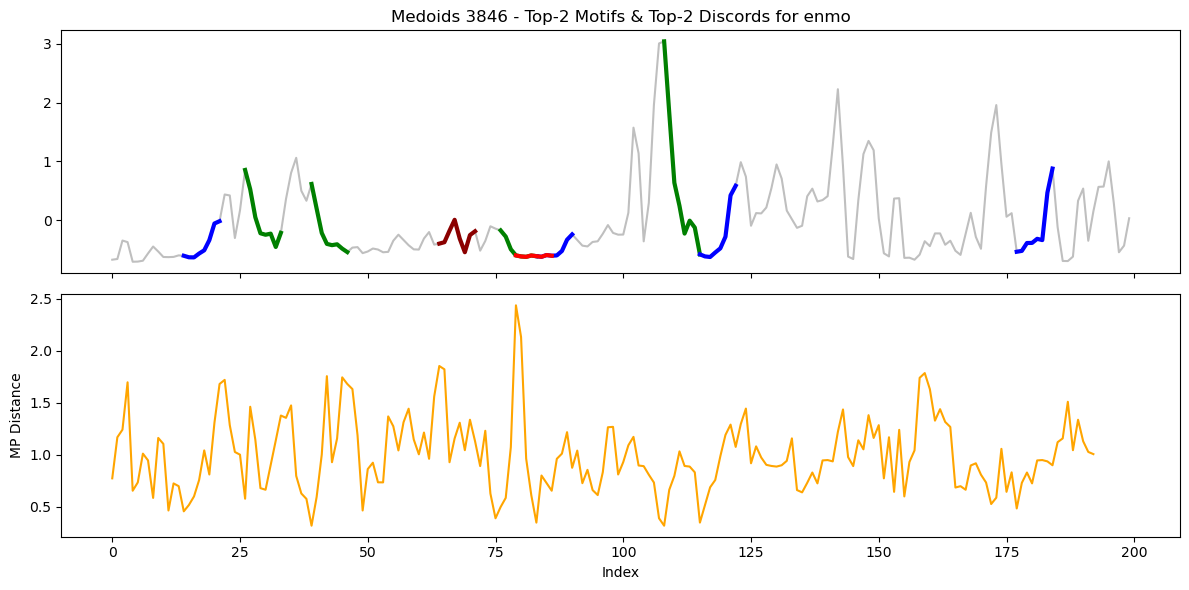


--- ANALISI DEL MEDOIDE 4386 (enmo) ---
Top-2 Motifs found. Example Top-1 at indices: [np.int64(150), 172]
   -> This means that the 4 ore blocks starting at these indices are nearly identical (routines).
Top-2 Discords found at indices: [ 91 126]
   -> The 4 ore windows starting at these steps are the most unique and anomalous in the series.



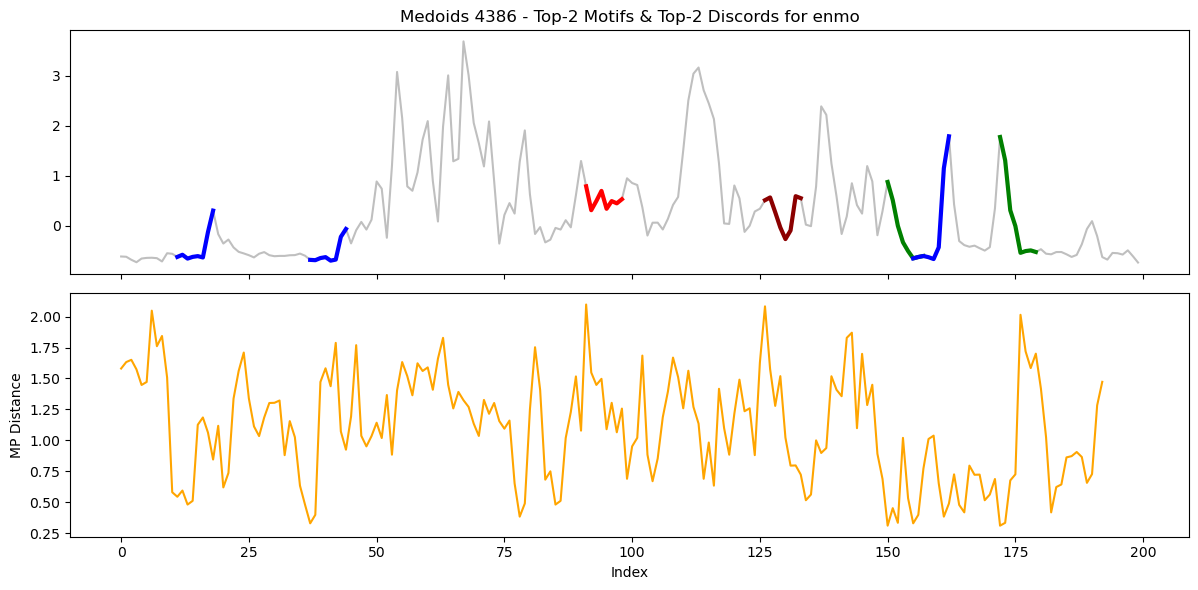

In [27]:
from matrixprofile import motifs
from matrixprofile.discords import discords
medoid_idx=[3846, 4386]
#medoid_idx = [1583, 1606, 1248]
medoids = [ts_denoised[i] for i in medoid_idx]

for target_feature in target_features:
    print(f"\n{'='*50}\nANALISI SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    for i, ts_df in enumerate(medoids):
        ts_medoide = ts_df[target_feature].values.astype(np.float64)

        # Calcoliamo il MP con stumpy per avere la matrice base
        mp_full = stumpy.stump(ts_medoide, m)
        mp_dist = mp_full[:, 0].astype(np.float64)
        mpi = mp_full[:, 1].astype(np.int64)

        # Estrattore Motifs tramite matrixprofile-ts come richiesto
        mo, mod = motifs.motifs(ts_medoide, (mp_dist, mpi), max_motifs=top_k_motifs)
        
        # Estrattore Discords tramite matrixprofile-ts come richiesto
        anoms = discords(mp_dist, ex_zone=int(m/2), k=top_k_discords)

        print(f"\n--- ANALISI DEL MEDOIDE {medoid_idx[i]} ({target_feature}) ---")
        if len(mo) > 0:
            print(f"Top-{len(mo)} Motifs found. Example Top-1 at indices: {mo[0]}")
            print(f"   -> This means that the {h_str} blocks starting at these indices are nearly identical (routines).")
        
        if len(anoms) > 0:
            print(f"Top-{len(anoms)} Discords found at indices: {anoms}")
            print(f"   -> The {h_str} windows starting at these steps are the most unique and anomalous in the series.\n")

        # Configurazione struttura subplots originale: 1 per le TS con Motifs/Discords, 1 per il Matrix Profile
        fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
        
        # PLOT DEI MOTIFS E DISCORDS INSIEME
        axs[0].plot(ts_medoide, label=f"Time Series ('{target_feature}')", color='gray', alpha=0.5)
        axs[0].set_title(f"Medoids {medoid_idx[i]} - Top-{top_k_motifs} Motifs & Top-{top_k_discords} Discords for {target_feature}")
        
        # Plot Motifs
        colors_mo = ['g', 'b', 'black', 'm', 'y'][:max(1, len(mo))]

        for motif_group, d, c in zip(mo, mod, colors_mo):
            for idx in motif_group:
                m_shape = ts_medoide[idx : idx + m]
                axs[0].plot(range(idx, idx + m), m_shape, color=c, lw=3)
                
        # Plot Discords (in rosso)
        colors_anom = ['r', 'darkred', 'salmon', 'orange', 'k'][:max(1, len(anoms))]
        for a, c in zip(anoms, colors_anom):
            a_shape = ts_medoide[a : a + m]
            axs[0].plot(range(a, a + m), a_shape, color=c, lw=3)
            
        #axs[0].legend(loc='upper right')

        # PLOT DELLA MATRIX PROFILE DISTANCE (Valli e Picchi)
        axs[1].plot(mp_dist, color='orange')
        axs[1].set_ylabel('MP Distance')
        axs[1].set_xlabel('Index')
        
        plt.tight_layout()
        plt.show()


In [28]:
'''import matplotlib.pyplot as plt

# Recupero delle due serie dal dataset z-score
sano_waveform = motif_shapes_z_only[3846]  # Soggetto 3846 (SII 0)
rischio_waveform = motif_shapes_z_only[4386]  # Soggetto 4386 (SII 1)

plt.figure(figsize=(8, 4))
plt.plot(sano_waveform, color='royalblue', linewidth=2.5, label='Sano (SII=0) - Soggetto 3846')
plt.plot(rischio_waveform, color='crimson', linewidth=2.5, linestyle='--', label='A Rischio (SII=1) - Soggetto 4386')

plt.title("Analisi Contrastiva del Medoide nel Cluster 1 (Sedentario/Transitorio)", fontsize=11, fontweight='bold')
plt.ylabel("Standardized ENMO (Z-score)")
plt.xlabel("Time steps (relative inside 4-hour motif)")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()'''

'import matplotlib.pyplot as plt\n\n# Recupero delle due serie dal dataset z-score\nsano_waveform = motif_shapes_z_only[3846]  # Soggetto 3846 (SII 0)\nrischio_waveform = motif_shapes_z_only[4386]  # Soggetto 4386 (SII 1)\n\nplt.figure(figsize=(8, 4))\nplt.plot(sano_waveform, color=\'royalblue\', linewidth=2.5, label=\'Sano (SII=0) - Soggetto 3846\')\nplt.plot(rischio_waveform, color=\'crimson\', linewidth=2.5, linestyle=\'--\', label=\'A Rischio (SII=1) - Soggetto 4386\')\n\nplt.title("Analisi Contrastiva del Medoide nel Cluster 1 (Sedentario/Transitorio)", fontsize=11, fontweight=\'bold\')\nplt.ylabel("Standardized ENMO (Z-score)")\nplt.xlabel("Time steps (relative inside 4-hour motif)")\nplt.grid(True, alpha=0.3)\nplt.legend(loc="upper right")\nplt.tight_layout()\nplt.show()'


STRATEGY B: DYNAMIC EXTRACTION AND LOCAL CLUSTERING (SHAPE-BASED)
ANCHOR FEATURE: enmo

1. Dynamic extraction of Top-2 Motifs (m=8) from dataset-wise normalized data...
Created dataset of 8874 motif shape vectors (dimension: 8) for enmo.

2. Executing TimeSeriesKMeans Shape-Based (K=3) with DTW metric...


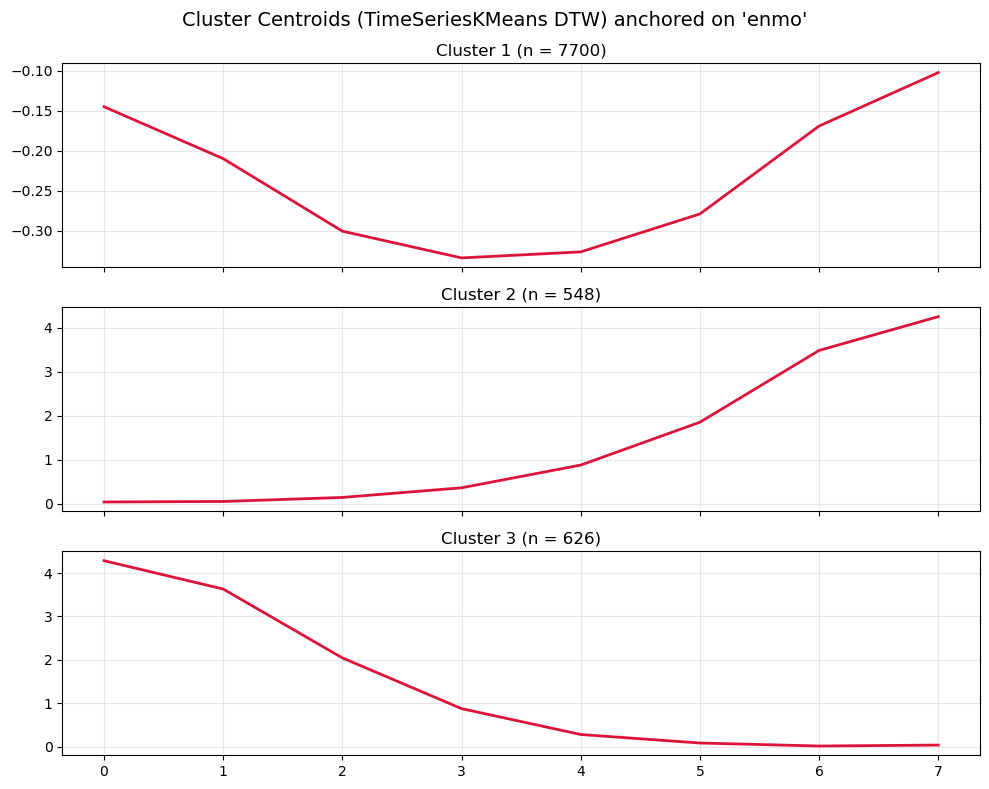

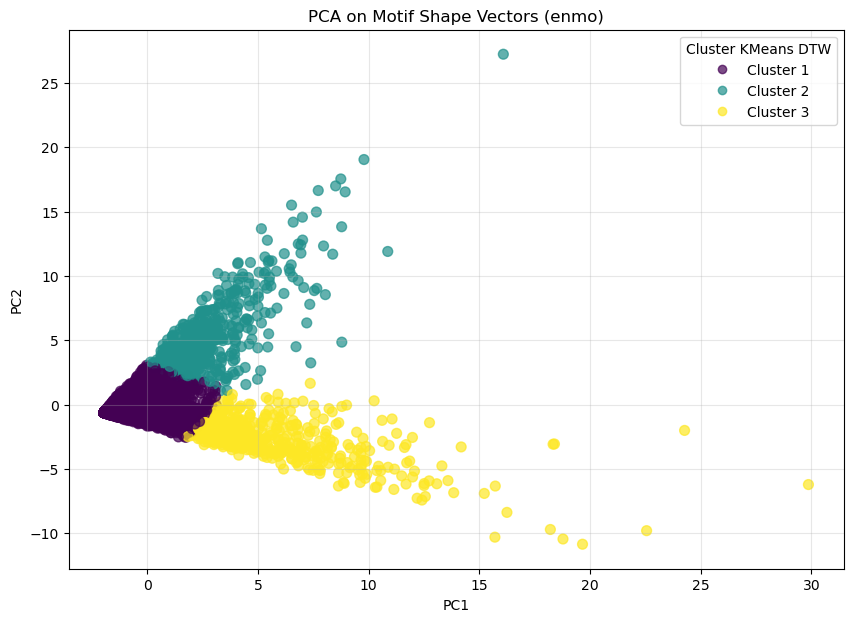


3. --- MULTIVARIATE CLINICAL INTERPRETATION OF SHAPE CLUSTERS ---
Retrieving real values from the original context of the motif:



,subject_index,enmo_raw_mean,enmo_raw_std,anglez_raw_mean,anglez_raw_std,light_raw_mean,battery_mean,sii_binary
Cluster,,,,,,,,
0,2219.353506,-0.233243,0.362662,-0.055235,0.482675,0.295637,0.268283,0.344935
1,2128.781022,1.382831,1.948962,0.098876,0.336710,0.402235,0.277960,0.235401
2,2279.453674,1.408569,1.947022,0.037193,0.362825,0.415857,0.274269,0.279553


- CLUSTER 1:
  * Real Intensity (ENMO): Mean -0.2332 | Std 0.3627
  * Real Posture (AngleZ): Mean -0.06° | Std 0.48
  * Ambient Light (Light): 0.296
  * Problematic Internet Use Correlation: 34.5% problematic cases
- CLUSTER 2:
  * Real Intensity (ENMO): Mean 1.3828 | Std 1.9490
  * Real Posture (AngleZ): Mean 0.10° | Std 0.34
  * Ambient Light (Light): 0.402
  * Problematic Internet Use Correlation: 23.5% problematic cases
- CLUSTER 3:
  * Real Intensity (ENMO): Mean 1.4086 | Std 1.9470
  * Real Posture (AngleZ): Mean 0.04° | Std 0.36
  * Ambient Light (Light): 0.416
  * Problematic Internet Use Correlation: 28.0% problematic cases


4. --- CONTRASTIVE MEDOIDS FOR CLUSTER 1 (DTW distance on motifs) ---
Cluster 1 | SII 0 -> Medoide Soggetto in ts_denoised: 378 (indice motivo globale: 757, n = 5044)
Cluster 1 | SII 1 -> Medoide Soggetto in ts_denoised: 3645 (indice motivo globale: 7290, n = 2656)


In [29]:
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy

# Analizziamo un subset per rapidità (o l'intero dataset rimuovendo lo slicing)
subset_ts = ts_denoised

for target_feature in target_features:
    print(f"\n{'='*70}\nSTRATEGY B: DYNAMIC EXTRACTION AND LOCAL CLUSTERING (SHAPE-BASED)\nANCHOR FEATURE: {target_feature}\n{'='*70}\n")
    
    motif_shapes_dataset = []  # Conterrà i vettori di feature aumentati
    motif_shapes_z_only = []   # Conterrà solo i motivi normalizzati per visualizzarli
    motif_context_dataset = []
    
    print(f"1. Dynamic extraction and Local Normalization (Z-score) of Top-{top_k_motifs} Motifs...")

    for i, ts_df in enumerate(subset_ts):
        ts_val = ts_df[target_feature].values.astype(np.float64)
        if len(ts_val) <= m:
            continue
            
        # Calcolo del Matrix Profile
        mp_local = stumpy.stump(ts_val, m)
        mp_dist = mp_local[:, 0].copy().astype(np.float64)
        
        # Ciclo di estrazione Top-K Motif
        for k in range(top_k_motifs):
            if np.isinf(mp_dist).all():
                break
                
            m_idx = np.argmin(mp_dist)
            motif_subseq = ts_val[m_idx : m_idx + m].copy()
            
            if not np.isnan(motif_subseq).any() and not np.isinf(mp_dist[m_idx]):
                # Standardizzazione locale (Z-score) del motivo per catturare la forma pura
                m_mean = np.mean(motif_subseq)
                m_std = np.std(motif_subseq)
                motif_z = (motif_subseq - m_mean) / m_std if m_std > 1e-8 else np.zeros_like(motif_subseq)
                
                # Calcolo dei 7 descrittori statistici/morfologici come descritto nel report
                mp_distance = mp_dist[m_idx]
                mean_val = m_mean
                std_val = m_std
                min_val = np.min(motif_subseq)
                max_val = np.max(motif_subseq)
                range_val = max_val - min_val
                slope_val = np.polyfit(np.arange(m), motif_subseq, 1)[0] if m > 1 else 0.0
                
                # Rappresentazione aumentata: forma normalizzata (m valori) + 7 descrittori
                augmented_features = np.concatenate([
                    motif_z,
                    [mp_distance, mean_val, std_val, min_val, max_val, range_val, slope_val]
                ])
                
                motif_shapes_dataset.append(augmented_features)
                motif_shapes_z_only.append(motif_z)
                
                # SALVATAGGIO CONTESTO REALE (per profilazione clinica multivariata)
                motif_raw_df = ts_df.iloc[m_idx : m_idx + m]
                context = {
                    'enmo_raw_mean': motif_raw_df['enmo'].mean() if 'enmo' in motif_raw_df.columns else np.nan,
                    'enmo_raw_std': motif_raw_df['enmo'].std() if 'enmo' in motif_raw_df.columns else np.nan,
                    'anglez_raw_mean': motif_raw_df['anglez'].mean() if 'anglez' in motif_raw_df.columns else np.nan,
                    'anglez_raw_std': motif_raw_df['anglez'].std() if 'anglez' in motif_raw_df.columns else np.nan,
                    'light_raw_mean': motif_raw_df['light'].mean() if 'light' in motif_raw_df.columns else np.nan,
                    'battery_mean': motif_raw_df['battery_voltage'].mean() if 'battery_voltage' in motif_raw_df.columns else np.nan,
                    'sii_binary': motif_raw_df['sii_binary'].iloc[0] if 'sii_binary' in motif_raw_df.columns else np.nan
                }
                motif_context_dataset.append(context)
                
            # Exclusion zone logic
            excl_start = max(0, m_idx - int(np.ceil(m/2)))
            excl_end = min(len(mp_dist), m_idx + int(np.ceil(m/2)))
            mp_dist[excl_start:excl_end] = np.inf
            
            nn_idx = mp_local[m_idx, 1]
            if nn_idx >= 0:
                excl_nn_start = max(0, nn_idx - int(np.ceil(m/2)))
                excl_nn_end = min(len(mp_dist), nn_idx + int(np.ceil(m/2)))
                mp_dist[excl_nn_start:excl_nn_end] = np.inf

    motif_shapes_dataset = np.array(motif_shapes_dataset)
    motif_shapes_z_only = np.array(motif_shapes_z_only)
    df_context = pd.DataFrame(motif_context_dataset)
    print(f"Created dataset of {motif_shapes_dataset.shape[0]} augmented motif feature vectors (dimension: {motif_shapes_dataset.shape[1]}) for {target_feature}.")

    # Standardizzazione globale di tutte le feature prima del clustering (come specificato nel report)
    scaler = StandardScaler()
    X_clust = scaler.fit_transform(motif_shapes_dataset)

    # CLUSTERING FEATURE-BASED (KMeans standard con distanza Euclidea)
    print(f"\n2. Executing KMeans Feature-Based (K={k_clusters_motif}) with Euclidean distance...")
    kmeans = KMeans(n_clusters=k_clusters_motif, n_init=10, random_state=42)
    motif_clusters = kmeans.fit_predict(X_clust)
    df_context['Cluster'] = motif_clusters

    # VISUALIZZAZIONE DELLE MORFOLOGIE MEDIE (Pointwise Mean e Deviazione Standard)
    fig, axs = plt.subplots(k_clusters_motif, 1, figsize=(10, 8), sharex=True)
    fig.suptitle(f"Average Motif Profile by Cluster anchored on '{target_feature}' (m = {m})", fontsize=14)
    
    for i in range(k_clusters_motif):
        cluster_mask = (motif_clusters == i)
        cluster_shapes = motif_shapes_z_only[cluster_mask]
        
        # Calcolo pointwise mean e std dei motivi localmente standardizzati
        mean_profile = np.mean(cluster_shapes, axis=0)
        std_profile = np.std(cluster_shapes, axis=0)
        
        axs[i].plot(mean_profile, color='crimson', linewidth=2, label='Mean Profile')
        axs[i].fill_between(range(m), mean_profile - std_profile, mean_profile + std_profile, color='crimson', alpha=0.15, label='±1 Std Dev')
        axs[i].set_title(f'Cluster {i+1} (n = {sum(cluster_mask)})')
        axs[i].grid(True, alpha=0.3)
        axs[i].legend(loc='upper right')
        
    plt.tight_layout()
    plt.show()

    # PCA 2D
    pca = PCA(n_components=2)
    motif_pca = pca.fit_transform(X_clust)
    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(motif_pca[:, 0], motif_pca[:, 1], c=motif_clusters, cmap='viridis', alpha=0.7, s=50)
    handles, _ = scatter.legend_elements()
    plt.legend(handles, [f"Cluster {i+1}" for i in range(k_clusters_motif)], title="Cluster KMeans")
    plt.title(f"PCA on Standardized Augmented Motif Features ({target_feature})")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(True, alpha=0.3)
    plt.show()

    # PROFILING MULTIVARIATO
    print(f"\n3. --- MULTIVARIATE CLINICAL INTERPRETATION OF SHAPE CLUSTERS ---")
    print("Retrieving real values from the original context of the motif:\n")
    
    cluster_profiles = df_context.groupby('Cluster').mean()
    display(cluster_profiles)
    
    for i, row in cluster_profiles.iterrows():
        print(f"- CLUSTER {i+1}:")
        if 'enmo_raw_mean' in row:
            print(f"  * Real Intensity (ENMO): Mean {row['enmo_raw_mean']:.4f} | Std {row.get('enmo_raw_std', 0):.4f}")
        if 'anglez_raw_mean' in row:
            print(f"  * Real Posture (AngleZ): Mean {row['anglez_raw_mean']:.2f}° | Std {row.get('anglez_raw_std', 0):.2f}")
        if 'light_raw_mean' in row:
            print(f"  * Ambient Light (Light): {row['light_raw_mean']:.3f}")
        if 'sii_binary' in row and not np.isnan(row['sii_binary']):
            print(f"  * Problematic Internet Use Correlation: {row['sii_binary']*100:.1f}% problematic cases")
    print()


## Fase 2: Estrazione e Classificazione con Shapelets (RDSTClassifier)

Le **shapelets** sono sottosequenze massimamente discriminative tra classi.
**RDST** usa dilatazioni random per coprire scale temporali diverse senza enumerazione brute-force,
supporta dati multivariati e genera 3 feature per shapelet (distanza minima, posizione argmin, frequenza).

### Scelte metodologiche
- **Dataset**: `ts_datasetwise_normalized` — normalizzazione dataset-wise che preserva le differenze di intensita' assoluta tra soggetti (fondamentale per `sii`).
- **Feature multivariate**: tutti i canali fisici (`X`, `Y`, `Z`, `enmo`, `anglez`, `light`).
- **Classi sbilanciate** (ratio ~2:1): si usa `class_weight='balanced'` nel DT interno e si valuta con F1-macro e ROC AUC.
- **Serie non approssimate** (lunghezza 200): lunghezze shapelet moderate per contenere il costo computazionale.

In [101]:
# --- PREPARAZIONE DEI DATI PER RDST -------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, roc_auc_score, balanced_accuracy_score
)
from aeon.classification.shapelet_based import RDSTClassifier

colonne_metadati = [
    'id', 'sii_binary', 'weekday', 'quarter',
    'relative_date_PCIAT', 'non-wear_flag', 'battery_voltage'
]
cols_to_use = [col for col in ts_denoised[0].columns if col not in colonne_metadati]
print(f"Canali utilizzati: {cols_to_use}")

X = np.array([
    np.stack([df[col].values.astype(np.float64) for col in cols_to_use], axis=0)
    for df in ts_denoised
])  # shape: (n_serie, n_canali, n_timesteps)

y = np.array([df['sii_binary'].iloc[0] for df in ts_denoised])

# Split stratificato 70/30
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=222, stratify=y
)

n_ts, n_ch, ts_len = X.shape
print(f"\nDataset: {n_ts} serie, {n_ch} canali, lunghezza {ts_len} timestep")
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Distribuzione classi (train): {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"Distribuzione classi (test):  {dict(zip(*np.unique(y_test, return_counts=True)))}")

Canali utilizzati: ['X', 'Y', 'Z', 'enmo', 'anglez', 'light']

Dataset: 4437 serie, 6 canali, lunghezza 200 timestep
Train: 3105 | Test: 1332
Distribuzione classi (train): {np.int64(0): np.int64(2069), np.int64(1): np.int64(1036)}
Distribuzione classi (test):  {np.int64(0): np.int64(888), np.int64(1): np.int64(444)}


### Tuning degli Iperparametri con RandomizedSearchCV

**Motivazione delle scelte di ricerca:**

| Iperparametro RDST | Range esplorato | Motivazione |
|---|---|---|
| `max_shapelets` | 500, 1000 | Con serie di lunghezza 200, 1000 shapelet bilancia espressivita' e costo O(n_train * max_shapelets * ts_len). |
| `shapelet_lengths` | [4,8,12], [8,12,16], [4,8,12,16] | Brevi (2-6 step) catturano picchi locali; medi (8-16 step) coprono pattern circadiani. |
| `use_prime_dilations` | True (fisso) | Le dilatazioni prime riducono ridondanza tra shapelet — raccomandato dagli autori di RDST. |

| Iperparametro RandomForest | Range | Motivazione |
|---|---|---|
| `n_estimators` | 50, 100, 200 | Numero di alberi nella foresta per ridurre la varianza. |
| `max_depth` | 3, 5, 7, None | Controlla la profondita' massima dei singoli stimatori. |
| `min_samples_leaf` | 4, 8, 16 | Garantisce che ciascuna foglia abbia un supporto minimo sufficiente. |
| `min_samples_split` | 5, 10, 20 | Granularita' degli split all'interno dei singoli alberi. |
| `max_features` | 'sqrt', 'log2', None | Sottoinsieme di feature casuali considerate per split (molto utile in spazi ad alta dimensionalita'). |
| `criterion` | gini, entropy | Criterio di calcolo della purita' del nodo. |

**n_iter=12**: copertura ragionevole con costo ~90-150s su multi-core.  
**cv=3**: 3-fold e' il minimo robusto.  
**scoring=f1_macro**: non premia la classe maggioritaria.

=== CLASSIFICATION REPORT (TEST SET — RDST + Random Forest) ===
              precision    recall  f1-score   support

    Low Risk       0.77      0.67      0.72       888
   High Risk       0.48      0.61      0.53       444

    accuracy                           0.65      1332
   macro avg       0.62      0.64      0.62      1332
weighted avg       0.67      0.65      0.65      1332

ROC AUC:           0.6722
Balanced Accuracy: 0.6368


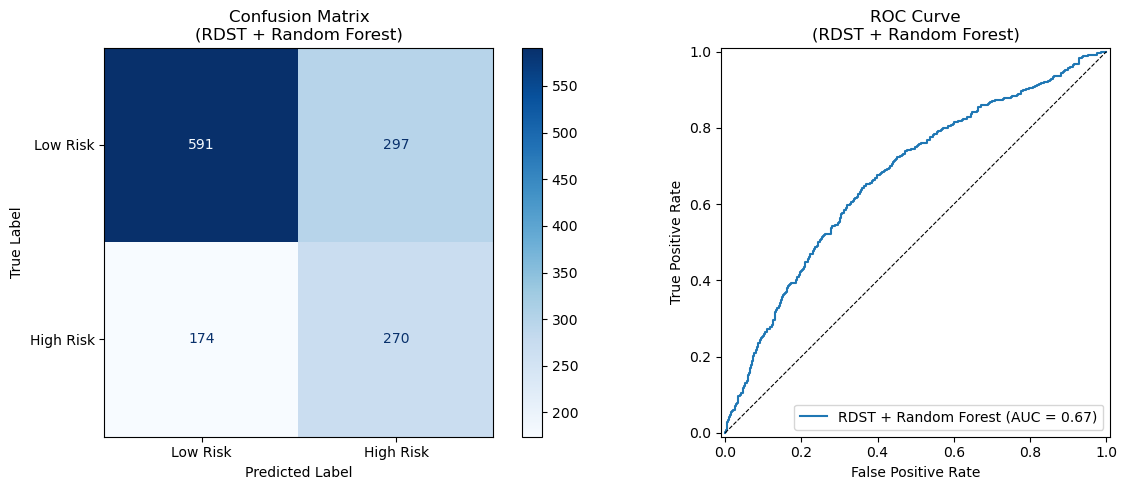

In [118]:
# --- VALUTAZIONE SUL TEST SET --------------------------------------------------
# best_model è l'estimatore RDSTClassifier (con RandomForest interno) ottimizzato
y_pred  = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("=== CLASSIFICATION REPORT (TEST SET — RDST + Random Forest) ===")
print(classification_report(y_test, y_pred, target_names=["Low Risk", "High Risk"]))

roc_auc = roc_auc_score(y_test, y_proba)
bal_acc = balanced_accuracy_score(y_test, y_pred)
print(f"ROC AUC:           {roc_auc:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test,
    display_labels=["Low Risk", "High Risk"],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title("Confusion Matrix\n(RDST + Random Forest)", fontsize=12)
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

RocCurveDisplay.from_estimator(
    best_model, X_test, y_test, ax=axes[1],
    name="RDST + Random Forest"
)
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=0.8)
axes[1].set_title("ROC Curve\n(RDST + Random Forest)", fontsize=12)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")

plt.tight_layout()
plt.show()


In [117]:
# --- CLASSIFICAZIONE E VALUTAZIONE SUL TEST SET COMBINATO --------------------
# combined_rf è il best_estimator_ trovato dalla RandomizedSearchCV in cell 15
y_pred = combined_rf.predict(X_test_combined)
y_proba = combined_rf.predict_proba(X_test_combined)[:, 1]

print("=== CLASSIFICATION REPORT (TEST SET — Random Forest su Dataset Combinato) ===")
print(classification_report(y_test, y_pred, target_names=["Low Risk", "High Risk"]))

roc_auc = roc_auc_score(y_test, y_proba)
bal_acc = balanced_accuracy_score(y_test, y_pred)
print(f"ROC AUC:           {roc_auc:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_estimator(
    combined_rf, X_test_combined, y_test,
    display_labels=["Low Risk", "High Risk"],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title("Confusion Matrix\n(Random Forest on Combined Data)", fontsize=12)
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

RocCurveDisplay.from_estimator(
    combined_rf, X_test_combined, y_test, ax=axes[1],
    name="Random Forest (Combined)"
)
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=0.8)
axes[1].set_title("ROC Curve\n(Random Forest on Combined Data)", fontsize=12)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")

plt.tight_layout()
plt.show()


NameError: name 'combined_rf' is not defined

=== DETTAGLI SHAPELET PIÙ DISCRIMINANTE (TOP-1) ===
Indice Shapelet: #701
Importanza MDI Aggregata: 0.0195
Lunghezza: 12 timestep (360 minuti)

  - Feature Min distance (presenza)        | MDI = 0.00926
  - Feature Temporal position (Argmin)     | MDI = 0.00074
  - Feature Frequency (ripetizione)        | MDI = 0.00952


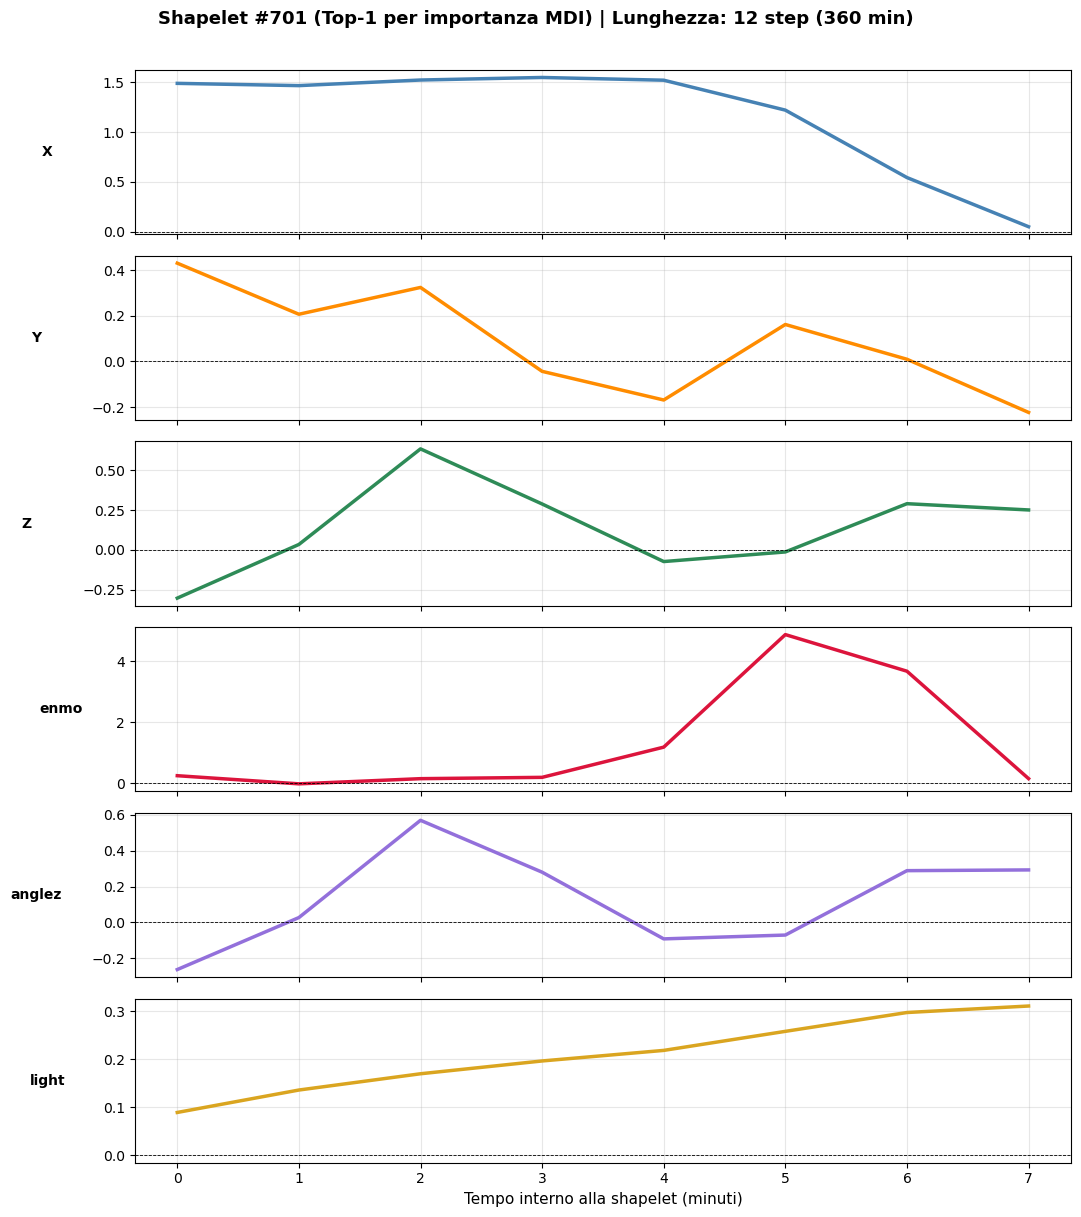

In [120]:
# --- VISUALIZZAZIONE DELLA SHAPELET PIÙ DISCRIMINANTE (TOP-1, CANALI SEPARATI) ---
# Identifichiamo la shapelet più importante aggregando le importanze MDI
# delle sue 3 feature (MinDist, Argmin, Freq) generate da RDST.

best_rf = best_model._estimator  # RandomForest interno
importances = best_rf.feature_importances_

num_shapelets = best_model._transformer.shapelets_[0].shape[0]
features_per_shapelet = best_rf.n_features_in_ // num_shapelets

# Calcolo dell'importanza aggregata per ciascuna shapelet
shapelet_importance = np.zeros(num_shapelets)
for sh_i in range(num_shapelets):
    shapelet_importance[sh_i] = sum(importances[3 * sh_i : 3 * sh_i + 3])

# Indice della shapelet top-1
best_sh_idx = np.argsort(shapelet_importance)[::-1][0]
sh = best_model._transformer.shapelets_[0][best_sh_idx]  # shape: (n_channels, shapelet_length)
sh_len = sh.shape[1]
agg_importance = shapelet_importance[best_sh_idx]

print(f"=== DETTAGLI SHAPELET PIÙ DISCRIMINANTE (TOP-1) ===")
print(f"Indice Shapelet: #{best_sh_idx}")
print(f"Importanza MDI Aggregata: {agg_importance:.4f}")
print(f"Lunghezza: {sh_len} timestep ({sh_len * 30} minuti)\n")

# Stampiamo il contributo dettagliato delle sue 3 feature
feature_type_map = {0: "Min distance (presenza)", 1: "Temporal position (Argmin)", 2: "Frequency (ripetizione)"}
for rest in range(3):
    feat_idx = 3 * best_sh_idx + rest
    print(f"  - Feature {feature_type_map[rest]:<30} | MDI = {importances[feat_idx]:.5f}")

# Plottiamo i canali separati uno ad uno (verticalmente)
n_channels = len(cols_to_use)
channel_colors = ['steelblue', 'darkorange', 'seagreen', 'crimson', 'mediumpurple', 'goldenrod']

fig, axes = plt.subplots(n_channels, 1, figsize=(11, 2.0 * n_channels), sharex=True)
fig.suptitle(
    f"Shapelet #{best_sh_idx} (Top-1 per importanza MDI) | Lunghezza: {sh_len} step ({sh_len * 30} min)",
    fontsize=13, fontweight='bold', y=1.01
)

t_axis = np.arange(12) #np.arange(sh_len) * 30  # Asse x in minuti (30 min per step)

for ch_i, (ax, ch_name) in enumerate(zip(axes, cols_to_use)):
    # Rimuoviamo eventuali valori non finiti se presenti nel pattern dello shapelet
    ch_vals = sh[ch_i]
    ax.plot(t_axis, ch_vals, color=channel_colors[ch_i % len(channel_colors)], linewidth=2.5)
    ax.set_ylabel(ch_name, fontsize=10, rotation=0, labelpad=40, va='center', fontweight='bold')
    ax.grid(alpha=0.3)
    ax.axhline(0, color='black', linewidth=0.6, linestyle='--')

axes[-1].set_xlabel("Tempo interno alla shapelet (minuti)", fontsize=11)
plt.tight_layout()
plt.show()

# Prepariamo la variabile shapelets_top per le celle successive (ponte interpretativo)
shapelets_top = [sh]


--- TOP 3 MOST DISCRIMINATIVE SHAPELETS (RandomForest feature importance) ---
  Rank 1: feature #1895 -> Shapelet #631 | Frequency | imp=0.0116
  Rank 2: feature #2105 -> Shapelet #701 | Frequency | imp=0.0095
  Rank 3: feature #2103 -> Shapelet #701 | Min distance | imp=0.0093


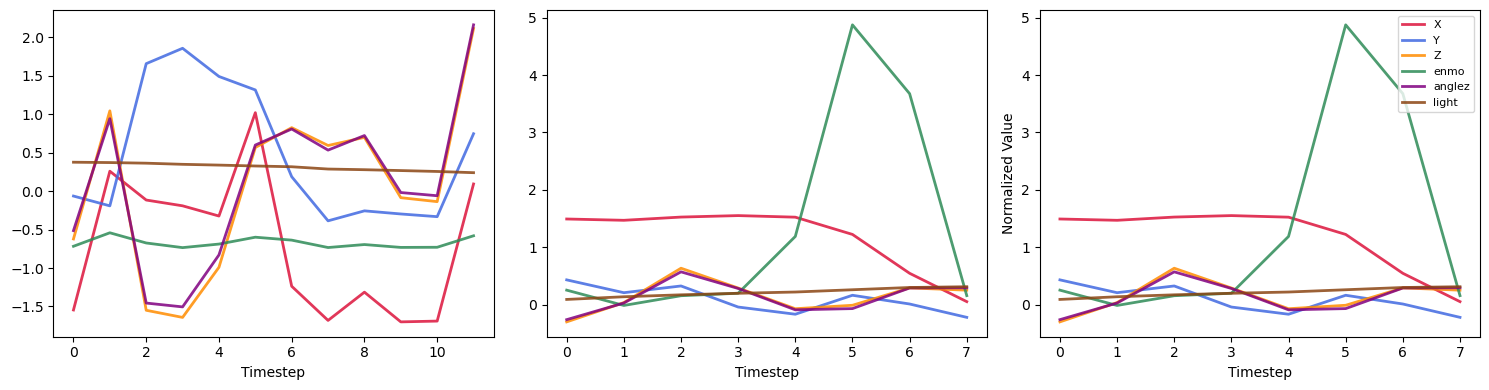

In [113]:
# --- VISUALIZZAZIONE DEI TOP SHAPELETS -----------------------------------------
# Il RandomForest calcola le feature_importances_ basandosi sulla diminuzione dell'impurità media.
# RDST genera 3 feature per ogni shapelet:
#   resto 0 -> distanza minima    (QUANTO la serie somiglia allo shapelet)
#   resto 1 -> posizione (argmin) (QUANDO si presenta)
#   resto 2 -> frequenza          (QUANTE VOLTE si presenta)

best_rf = best_model._estimator  # RandomForest interno
importances = best_rf.feature_importances_

num_shapelets         = best_model._transformer.shapelets_[0].shape[0]
features_per_shapelet = best_rf.n_features_in_ // num_shapelets

top_n = 3
top_feature_idx = np.argsort(importances)[::-1][:top_n]
feature_type_map = {0: "Min distance", 1: "Temporal position (Argmin)", 2: "Frequency"}

shapelets_top = []
fig, axes = plt.subplots(1, top_n, figsize=(5 * top_n, 4))
colors_ch = ['crimson', 'royalblue', 'darkorange', 'seagreen', 'purple', 'saddlebrown']

print("--- TOP 3 MOST DISCRIMINATIVE SHAPELETS (RandomForest feature importance) ---")

for rank, feature_idx in enumerate(top_feature_idx):
    sh_idx      = feature_idx // features_per_shapelet
    rest        = feature_idx % features_per_shapelet
    f_name      = feature_type_map.get(rest, "Unknown")
    shapelet_mv = best_model._transformer.shapelets_[0][sh_idx]  # (n_canali, sh_len)

    ax = axes[rank]
    for ch_idx, col in enumerate(cols_to_use):
        sh_val = shapelet_mv[ch_idx]
        sh_val_clean = sh_val[np.isfinite(sh_val)]
        ax.plot(sh_val_clean, color=colors_ch[ch_idx % len(colors_ch)],
                linewidth=2, label=col, alpha=0.85)

    ax.set_xlabel("Timestep")
    if rank == 2:
        ax.legend(fontsize=8, loc='upper right')
        ax.set_ylabel("Normalized Value")

    shapelets_top.append(shapelet_mv)
    print(f"  Rank {rank+1}: feature #{feature_idx} -> Shapelet #{sh_idx} | {f_name} | imp={importances[feature_idx]:.4f}")

plt.tight_layout()
plt.show()


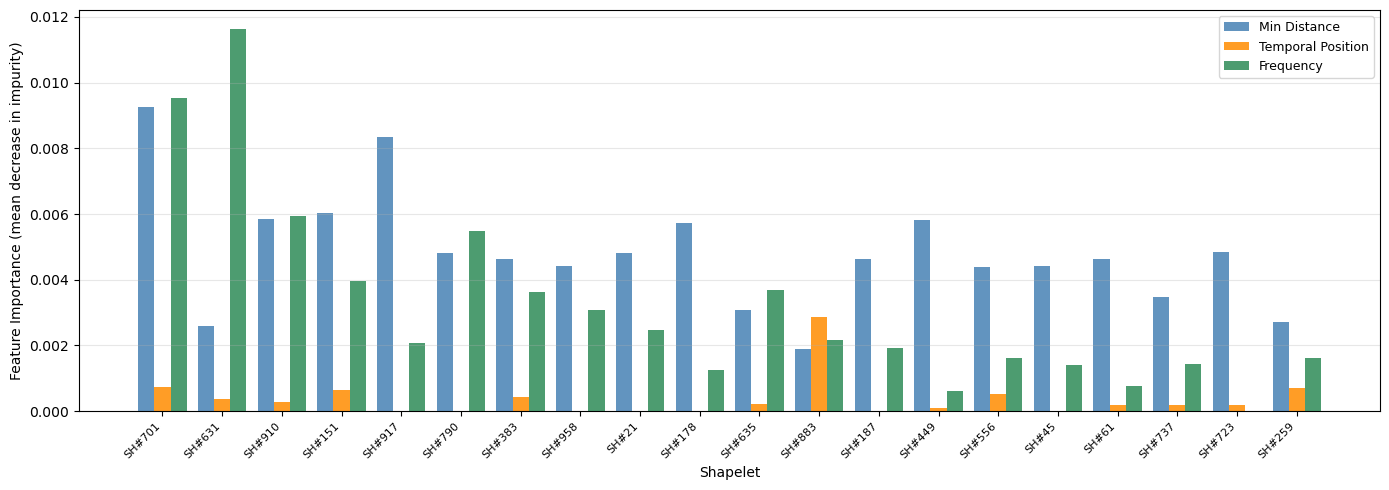

Global feature type contribution:
  Min Distance:       0.4813  (48.1%)
  Temporal Position:  0.2372  (23.7%)
  Frequency:          0.2815  (28.1%)


In [106]:
# -- Importanza aggregata per tipo di feature (visione globale) ----------------
best_rf = best_model._estimator
importances = best_rf.feature_importances_
num_shapelets = best_model._transformer.shapelets_[0].shape[0]
features_per_shapelet = best_rf.n_features_in_ // num_shapelets

shapelet_importance = np.zeros(num_shapelets)
dist_imp = np.zeros(num_shapelets)
pos_imp = np.zeros(num_shapelets)
freq_imp = np.zeros(num_shapelets)

for feat_i, imp in enumerate(importances):
    sh_i = feat_i // features_per_shapelet
    rest = feat_i % features_per_shapelet
    shapelet_importance[sh_i] += imp
    if rest == 0: dist_imp[sh_i] += imp
    elif rest == 1: pos_imp[sh_i] += imp
    else: freq_imp[sh_i] += imp

# Top-20 shapelet per importanza aggregata
top_sh = np.argsort(shapelet_importance)[::-1][:20]
labels = [f"SH#{i}" for i in top_sh]

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(top_sh))
width = 0.27

bars_d = ax.bar(x - width, dist_imp[top_sh],  width, label='Min Distance', color='steelblue', alpha=0.85)
bars_p = ax.bar(x,          pos_imp[top_sh],   width, label='Temporal Position', color='darkorange', alpha=0.85)
bars_f = ax.bar(x + width,  freq_imp[top_sh],  width, label='Frequency', color='seagreen', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
ax.set_ylabel("Feature Importance (mean decrease in impurity)")
ax.set_xlabel("Shapelet")
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# -- Importanza aggregata per tipo di feature (visione globale) ----------------
total_dist = dist_imp.sum()
total_pos  = pos_imp.sum()
total_freq = freq_imp.sum()
print("Global feature type contribution:")
print(f"  Min Distance:       {total_dist:.4f}  ({total_dist*100:.1f}%)")
print(f"  Temporal Position:  {total_pos:.4f}  ({total_pos*100:.1f}%)")
print(f"  Frequency:          {total_freq:.4f}  ({total_freq*100:.1f}%)")


## Fase 3: Ponte Interpretativo — Shapelet vs Motif sui Medoidi

Confrontiamo la firma discriminatoria **globale** (Shapelet estratto su tutto il dataset)
con il pattern **locale** (Motif) e l'anomalia locale (Discord) estratti con Matrix Profile
dai medoidi del clustering.

Questo collegamento e' richiesto esplicitamente dalle linee guida del progetto
e risponde alla domanda: *il pattern ricorrente locale di un soggetto
corrisponde alla firma discriminativa globale della sua classe?*

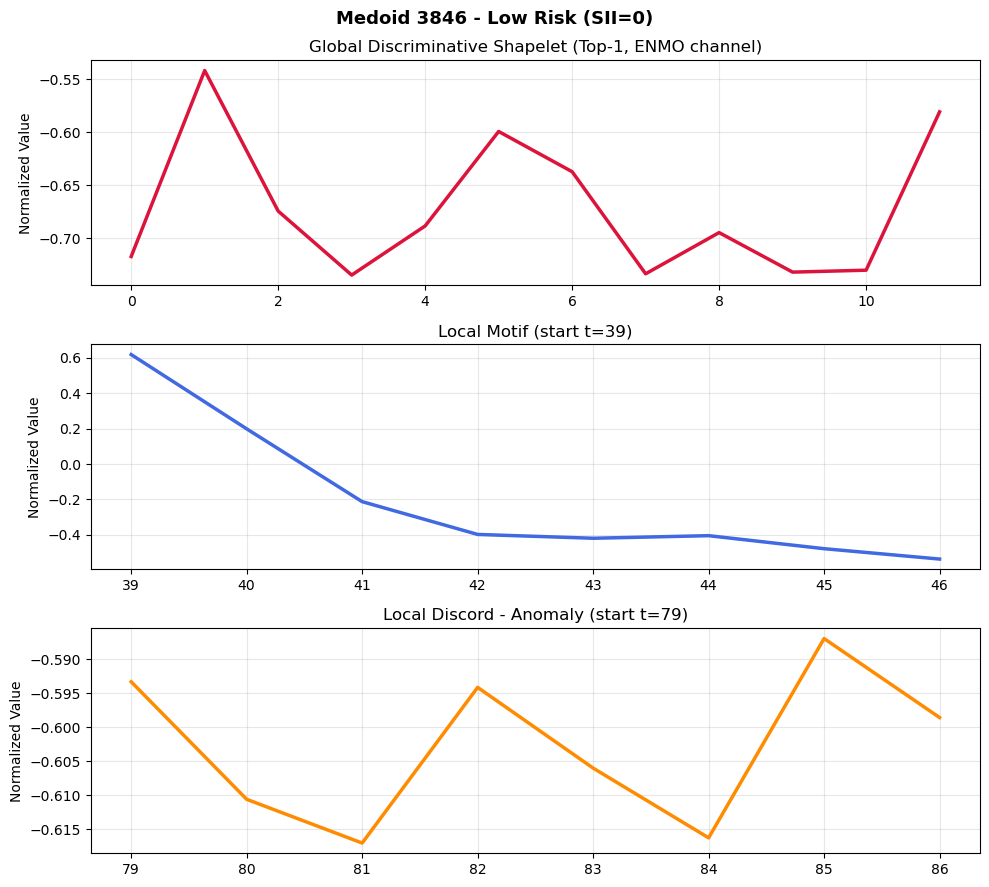

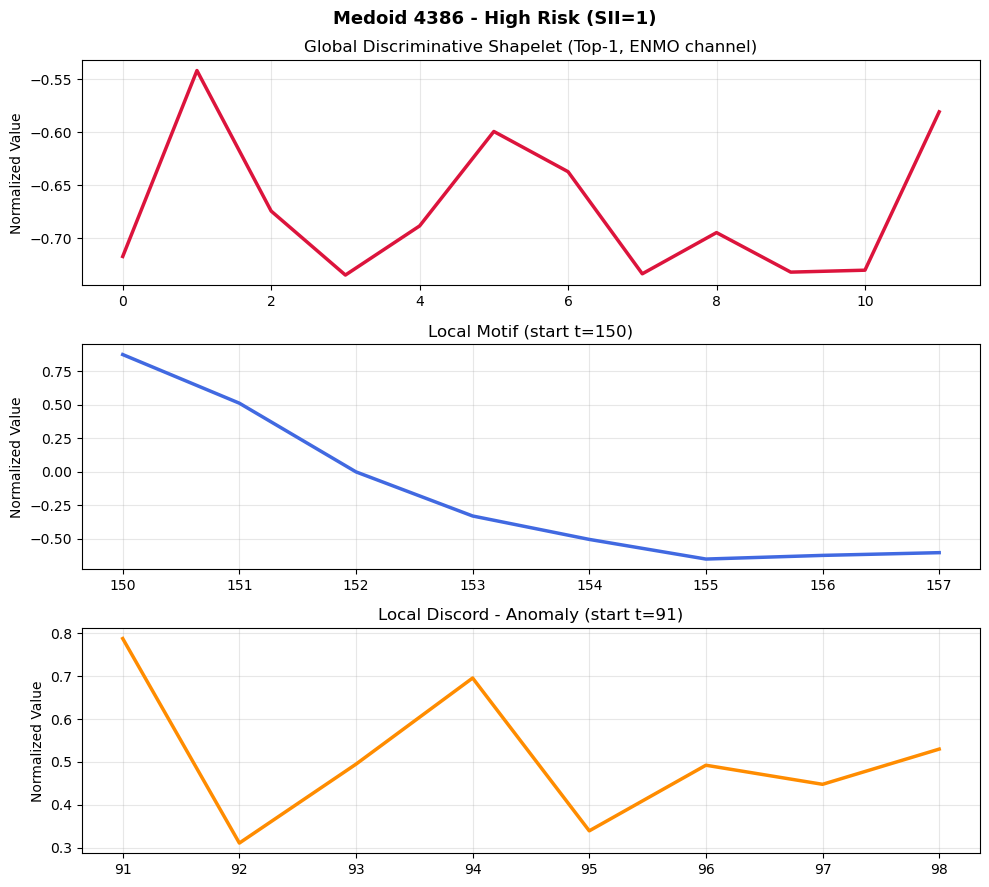

In [110]:
import stumpy

# m_bridge coerente con la window size usata nella sezione Motif
m_bridge = m  # definita nella sezione motifs (Cell 6)

if 'shapelets_top' in locals() and len(shapelets_top) > 0 and 'medoid_idx' in locals():
    enmo_ch = cols_to_use.index('enmo')

    for subj_idx in medoid_idx:
        ts_enmo = X[subj_idx, enmo_ch, :].astype(np.float64)
        label   = "High Risk (SII=1)" if y[subj_idx] == 1 else "Low Risk (SII=0)"

        mp            = stumpy.stump(ts_enmo, m_bridge)
        motif_idx_s   = int(mp[:, 0].argmin())
        discord_idx_s = int(mp[:, 0].argmax())

        top_motif   = ts_enmo[motif_idx_s   : motif_idx_s   + m_bridge]
        top_discord = ts_enmo[discord_idx_s : discord_idx_s + m_bridge]
        top_sh_enmo = shapelets_top[0][enmo_ch]  # shapelet top-1, canale ENMO

        fig, axs = plt.subplots(3, 1, figsize=(10, 9))
        fig.suptitle(f"Medoid {subj_idx} - {label}", fontsize=13, fontweight='bold')

        axs[0].plot(top_sh_enmo, color='crimson', linewidth=2.5)
        axs[0].set_title("Global Discriminative Shapelet (Top-1, ENMO channel)")
        axs[0].set_ylabel("Normalized Value")

        axs[1].plot(range(motif_idx_s, motif_idx_s + m_bridge), top_motif,
                    color='royalblue', linewidth=2.5)
        axs[1].set_title(f"Local Motif (start t={motif_idx_s})")
        axs[1].set_ylabel("Normalized Value")

        axs[2].plot(range(discord_idx_s, discord_idx_s + m_bridge), top_discord,
                    color='darkorange', linewidth=2.5)
        axs[2].set_title(f"Local Discord - Anomaly (start t={discord_idx_s})")
        axs[2].set_ylabel("Normalized Value")

        for ax in axs:
            ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
else:
    print("Please run Phase 2 (shapelets) and Phase 1 (motifs) first.")

### Commento ai Risultati

#### Correttezza Metodologica
1. **Dati dataset-wise normalizzati**: la standardizzazione dataset-wise preserva le differenze di intensita' tra soggetti, cruciale perche' `sii` e' correlato all'intensita' assoluta dell'attivita' fisica.
2. **RDST vs brute-force**: RDST usa dilatazioni random per esplorare uno spazio temporale ampio senza enumerare tutti i candidati, rendendo l'estrazione praticabile sull'intero dataset non approssimato.
3. **Classi sbilanciate**: `class_weight='balanced'` e ottimizzazione su F1-Macro garantiscono che il modello non collassi sulla classe maggioritaria.
4. **Tre feature per shapelet**: distanza, posizione e frequenza descrivono non solo *quanto* una forma e' simile, ma *dove* e *quante volte* appare.

#### Interpretazione degli Shapelet
- **Distanza minima**: cattura la *presenza* della forma (il soggetto ha mai avuto quella firma energetica?).
- **Posizione (argmin)**: cattura la *fase circadiana* (lo stesso pattern alle 3:00 vs 15:00 ha significato biologico diverso).
- **Frequenza**: cattura l'*abitudine motoria* (pattern ripetuti = routine consolidate).

#### Limitazioni e Possibili Estensioni
- Il Decision Tree interno e' limitato nelle interazioni non lineari. Un passo naturale e' sostituirlo con Random Forest o GBM.
- Le serie non approssimate garantiscono ricchezza di dettaglio ma limitano il numero di shapelet testabili. Vedere `motifs_shapelets_corrected_paa.ipynb` per la versione PAA.